# Returns Are Hard to Predict. Is Volatility Easier?

The weak-form **Efficient Market Hypothesis** suggests that historical market information should not provide a systematic opportunity to earn abnormal risk-adjusted returns. However, limited predictability in return direction does not imply that all features of returns are unpredictable. Return magnitudes can exhibit persistence, with large movements tending to cluster. This motivates investigating whether past returns help forecast future volatility.

This notebook studies volatility clustering and compares variance forecasting models. It does not directly test the Efficient Market Hypothesis or establish that volatility is easier to predict than returns.

We will test whether daily S&P 500 volatility can be forecast from past returns, and compare a historical-variance baseline, rolling variance, EWMA and GARCH(1,1).

**Research questions**
1. Do daily returns show little linear autocorrelation while their squared values show dependence?
2. Do time-varying variance forecasts improve on a constant historical-variance benchmark out of sample?
3. Does GARCH(1,1) achieve lower QLIKE loss than EWMA on the test period?

## Setup and data

We use daily closing levels of the S&P 500 price index (`^GSPC`). Daily log returns are

$$r_t = 100\log(P_t/P_{t-1})$$

The mean daily return is very small compared with its volatility, so we rely on a practical **approximately zero-mean assumption** when evaluating forecasts.

Since the conditional variance is not directly observable and the expected mean is minimal, we can use the squared return as a proxy when testing our models. This is justified by the variance decomposition:

$$E[r_t^2\mid\mathcal F_{t-1}] = \sigma_t^2 + E[r_t\mid\mathcal F_{t-1}]^2$$

When the conditional mean ($E[r_t\mid\mathcal F_{t-1}]$) is near zero, the squared return ($r_t^2$) is an approximately unbiased (but noisy) proxy for the variance ($\sigma_t^2$).

The models treat the mean differently: EWMA uses raw squared returns (an assumed zero mean), the rolling variance subtracts the mean of its window, and GARCH estimates a constant mean $\mu$. All forecasts are scored against $r_t^2$ rather than $(r_t-\mu)^2$. With $\hat\mu \approx 0.08$ in the GARCH fit below, $\hat\mu^2 \approx 0.006$, so the effect on the comparison is small.

In [1]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="acorr_lm currently returns a plain tuple",
    category=FutureWarning
)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.stattools import adfuller
import statsmodels.api as sm
from scipy.stats import norm
from arch import arch_model

TICKER = "^GSPC"
START_DATE = "2010-01-01"
END_DATE = "2026-10-09"  # yfinance end date is exclusive

print(f"Data: {TICKER} from {START_DATE} to {END_DATE} (end-exclusive)")

Data: ^GSPC from 2010-01-01 to 2026-10-09 (end-exclusive)


In [3]:
raw = yf.download(
    TICKER,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False,
)

if raw.empty:
    raise ValueError("No price data were downloaded. Check the ticker, dates or connection.")

# Handle yfinance's single-ticker MultiIndex columns as well as flat columns
prices = raw["Close"]
if isinstance(prices, pd.DataFrame):
    prices = prices.iloc[:, 0]
prices = prices.dropna().rename("price")

returns = (100 * np.log(prices / prices.shift(1))).dropna().rename("return")
squared_returns = (returns**2).rename("squared_return")

data = pd.concat([prices, returns, squared_returns], axis=1).dropna()

print(f"Observations: {len(returns):,}")
print(f"Period: {returns.index.min().date()} to {returns.index.max().date()}")
display(data.head())
display(returns.describe().to_frame("Daily log returns (%)"))

Observations: 4,216
Period: 2010-01-05 to 2026-10-08


,price,return,squared_return
Date,,,
2010-01-05,1136.520020,0.311083,0.096773
2010-01-06,1137.140015,0.054537,0.002974
2010-01-07,1141.689941,0.399322,0.159458
2010-01-08,1144.979980,0.287758,0.082805
2010-01-11,1146.979980,0.174523,0.030458


,Daily log returns (%)
count,4216.000000
mean,0.045655
std,1.083126
min,-12.765220
25%,-0.381884
50%,0.068894
75%,0.569126
max,9.089488


## Split data into fitting, validation and test periods

We will first divide the data in 80/20 for train/test. Then, the train set will be divided again in 80/20, and the 20% will be used for validation of model settings, like parameter selection.

In [4]:
test_split = int(len(returns) * 0.80)
train_returns = returns.iloc[:test_split]
test_returns = returns.iloc[test_split:]

validation_split = int(len(train_returns) * 0.80)
fit_returns = train_returns.iloc[:validation_split]
validation_returns = train_returns.iloc[validation_split:]

splits = {
    "Fit": fit_returns,
    "Validation": validation_returns,
    "Test": test_returns,
}
for name, series in splits.items():
    print(
        f"{name:10s}: {len(series):4d} observations | "
        f"{series.index.min().date()} to {series.index.max().date()}"
    )

assert fit_returns.index.max() < validation_returns.index.min()
assert validation_returns.index.max() < test_returns.index.min()

Fit       : 2697 observations | 2010-01-05 to 2020-09-21
Validation:  675 observations | 2020-09-22 to 2023-05-26
Test      :  844 observations | 2023-05-30 to 2026-10-08


## Explore returns and volatility clustering

Large absolute returns often appear close together, and calculating autocorrelation in squared returns is a simple way to examine this clustering. This is evidence of dependence in return magnitudes, not proof that volatility is predictable.

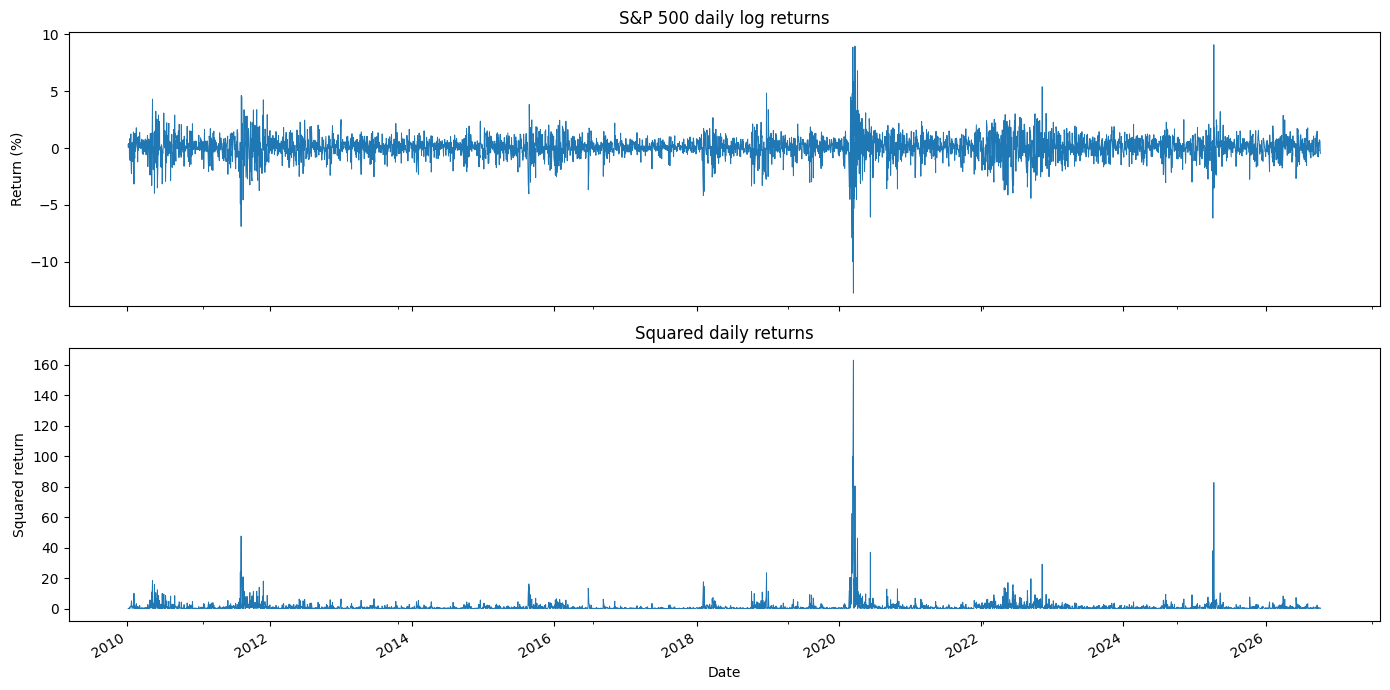

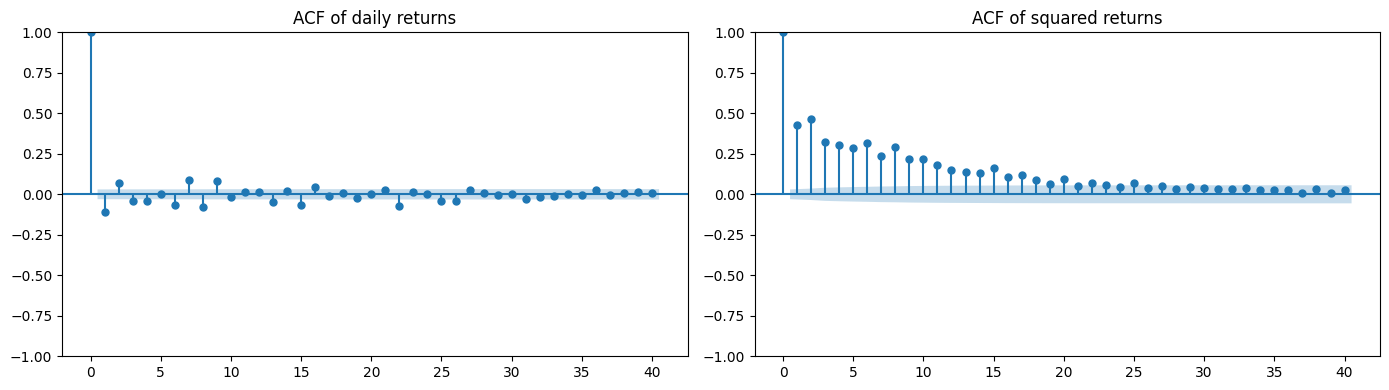

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
returns.plot(ax=axes[0], linewidth=0.7)
axes[0].set_title("S&P 500 daily log returns")
axes[0].set_ylabel("Return (%)")

squared_returns.plot(ax=axes[1], linewidth=0.7)
axes[1].set_title("Squared daily returns")
axes[1].set_ylabel("Squared return")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(returns, lags=40, ax=axes[0], title="ACF of daily returns")
plot_acf(squared_returns, lags=40, ax=axes[1], title="ACF of squared returns")
plt.tight_layout()
plt.show()

Returns may have little linear autocorrelation while squared returns show stronger autocorrelation. This motivates testing models that forecast variance rather than the direction of returns.

## Diagnostics on the fitting sample

After the visual check with ACF plots, we will run formal statistical tests to check for serial dependence, conditional heteroskedasticity and stationarity:

- **Ljung-Box Test:** Checks if past data maintains a linear relationship with current data across multiple time lags.
  
  - $H_0$: No autocorrelation in the data.
  - $H_1$: Serial correlation exists in the data.

- **ARCH-LM Test:** Specifically checks for volatility clustering (ARCH-type dependence) by testing for autocorrelation in the squared returns.

  - $H_0$: No ARCH effects exist (variance is constant / homoskedastic).
  - $H_1$: ARCH effects are present (volatility clustering exists / conditional heteroskedasticity).

- **ADF (Augmented Dickey-Fuller) Test:** Checks for a unit root to support the assumption that our returns are stationary.

  - $H_0$: A unit root is present (the time series is non-stationary).
  - $H_1$: No unit root is present.

We will run these on the fitting sample to keep the test period untouched until final evaluation.

In [6]:
# Ljung-Box
ljung_box_returns = acorr_ljungbox(fit_returns, lags=[10, 20], return_df=True)
ljung_box_squared = acorr_ljungbox(fit_returns**2, lags=[10, 20], return_df=True)

# Engle ARCH-LM H
arch_res = het_arch(
    fit_returns,
    nlags=10,
    result_object=True
)

arch_lm_stat = arch_res.lm
arch_lm_pvalue = arch_res.lmpval
arch_f_stat = arch_res.fval
arch_f_pvalue = arch_res.fpval

# ADF
adf_res = adfuller(fit_returns, autolag="AIC", result_object=True)

adf_stat = adf_res.statistic
adf_pvalue = adf_res.pvalue
adf_used_lags = adf_res.lags
adf_nobs = adf_res.nobs
adf_critical = adf_res.critical_values

diagnostic_summary = pd.DataFrame([
    {"Test": "Ljung-Box: returns", "Statistic": ljung_box_returns.loc[10, "lb_stat"], "p-value": ljung_box_returns.loc[10, "lb_pvalue"], "Lags": 10},
    {"Test": "Ljung-Box: squared returns", "Statistic": ljung_box_squared.loc[10, "lb_stat"], "p-value": ljung_box_squared.loc[10, "lb_pvalue"], "Lags": 10},
    {"Test": "ARCH-LM", "Statistic": arch_lm_stat, "p-value": arch_lm_pvalue, "Lags": 10},
    {"Test": "ADF: returns", "Statistic": adf_stat, "p-value": adf_pvalue, "Lags": adf_used_lags},
])
display(diagnostic_summary)
print("Ljung-Box results for returns:")
display(ljung_box_returns)
print("Ljung-Box results for squared returns:")
display(ljung_box_squared)
print("\nADF 5% critical value:", round(adf_critical["5%"], 4), " vs statistic: ", round(adf_stat, 4))

,Test,Statistic,p-value,Lags
0,Ljung-Box: returns,237.624033,2.160581e-45,10
1,Ljung-Box: squared returns,3419.380480,0.000000e+00,10
2,ARCH-LM,1068.958097,2.590994e-223,10
3,ADF: returns,-11.503050,4.443479e-21,26


Ljung-Box results for returns:


,lb_stat,lb_pvalue
10,237.624033,2.160581e-45
20,297.779857,2.295264e-51


Ljung-Box results for squared returns:


,lb_stat,lb_pvalue
10,3419.380480,0.0
20,3977.273968,0.0



ADF 5% critical value: -2.8626  vs statistic:  -11.5031


- **ADF Test (Stationarity):** The p-value is practically zero and the test statistic (-11.50) is far more negative than the 5% critical value (-2.8626). This result supports stationarity, consistent with the assumptions of the models used below.

- **Ljung-Box on Squared Returns & ARCH-LM Test (Heteroskedasticity):** Both tests evaluate variance predictability. The test statistics are huge (3419.38 and 1068.95) and the p-values are effectively zero. This rejects the null hypotheses of constant variance and we conclude that there is strong evidence of ARCH effects and volatility clustering in the sample.

- **Ljung-Box on Raw Returns (Serial Correlation):** The p-value here means we also reject the null hypothesis of no autocorrelation in the raw returns at the tested lags. While the Efficient Market Hypothesis (*) suggests raw returns shouldn't be predictable, finding small but statistically significant autocorrelation is extremely common in large daily index datasets due to market microstructure effects (like non-synchronous trading across 500 different stocks). However, the Ljung–Box test alone cannot establish the cause of the observed dependence.

*(\*) The weak form of the Efficient Market Hypothesis (EMH) states that prices already reflect the information in past prices and returns, so rules based only on that history should not earn consistent abnormal risk-adjusted returns. A statistically significant autocorrelation does not by itself show that such returns are available, and this notebook does not test it.*


## Forecasting methods

All forecasts are aligned to the date of the return they predict. That is, a variance forecast for date *t* is calculated using only the return data available up to day *t-1*.

- **Historical variance:** A constant benchmark estimated from the pre-test (training) sample.
- **Rolling variance:** The sample variance over a fixed trailing window.
- **EWMA (Exponentially Weighted Moving Average):** Updates variance recursively, applying a decay factor ($\lambda$) to give more weight to recent squared returns:
$$\sigma_t^2 = \lambda \sigma_{t-1}^2 + (1 - \lambda) r_{t-1}^2$$

- **GARCH(1,1):** Estimates how past shocks and past conditional variance relate to current variance. As discussed, it assumes returns have a constant mean $(\mu)$, and the difference between the actual return and that mean is the unexpected shock $(\varepsilon_t)$.
$$r_t = \mu + \varepsilon_t, \qquad \varepsilon_t = \sigma_{t}z_t, \quad z_{t}\sim N(0,1)$$
$$\sigma_{t}^2 = \omega + \alpha \varepsilon_{t-1}^2 + \beta \sigma_{t-1}^2$$

  Here, $\alpha, \beta, \omega \ge 0$ to ensure the variance is always positive. The constraint $\alpha + \beta < 1$ guarantees mean-reversion, ensuring that after a big market shock, volatility will eventually go back to its historical average.

  *(Note: Assuming $z_{t}\sim t(\nu)$ to account for heavy tails, or implementing an asymmetric GARCH model to capture the leverage effect, are highly relevant extensions but are left for future work).*

In [7]:
def rolling_variance_forecast(return_series, window):
    """Forecast target-date variance using the previous window returns"""
    return (return_series.rolling(window=window).std()**2).shift(1).rename(
        f"rolling_variance_{window}"
    )


def ewma_variance_forecast(return_series, lam, init_window=20):
    """
    One-step-ahead EWMA
    The first forecast is the variance of the initial init_window returns.
    Later forecasts use the previous forecast and the latest observed return.
    """
    if not 0 < lam < 1:
        raise ValueError("lam must be between 0 and 1.")
    if init_window < 2:
        raise ValueError("init_window must be at least 2.")
    if len(return_series) <= init_window:
        raise ValueError("Need more observations than init_window.")

    variance = pd.Series(np.nan, index=return_series.index, dtype=float)
    # First forecast: variance of the init_window returns
    variance.iloc[init_window] = return_series.iloc[:init_window].var()

    for i in range(init_window + 1, len(return_series)):
        variance.iloc[i] = (
            lam * variance.iloc[i - 1]
            + (1 - lam) * return_series.iloc[i - 1] ** 2
        )

    return variance.rename(f"ewma_variance_{lam}")


def garch_periodic_forecast(return_series, first_target, end_position, refit_every):
    """GARCH(1,1) with periodic parameter refitting"""
    if refit_every < 1:
        raise ValueError("refit_every must be at least 1.")

    rows = []
    current_params = None
    last_refit_date = None
    current_convergence_flag = None

    for i in range(first_target, end_position):
        history = return_series.iloc[:i]
        model = arch_model(
            history, mean="Constant", vol="GARCH", p=1, q=1, dist="normal"
        )
        if current_params is None or (i - first_target) % refit_every == 0:
            fitted = model.fit(disp="off")
            current_params = fitted.params
            current_convergence_flag = int(fitted.convergence_flag)
            last_refit_date = history.index[-1]
        else:
            fitted = model.fix(current_params)

        forecast = fitted.forecast(horizon=1)
        row = {
            "garch_variance": float(forecast.variance.iloc[-1, 0]),
            "last_parameter_refit": last_refit_date,
            "convergence_flag": current_convergence_flag,
        }
        for parameter in ["mu", "omega", "alpha[1]", "beta[1]"]:
            row[parameter] = float(current_params.get(parameter, np.nan))
        row["alpha_plus_beta"] = row["alpha[1]"] + row["beta[1]"]
        rows.append(row)

    target_index = return_series.index[first_target:end_position]
    return pd.DataFrame(rows, index=target_index)

## GARCH fit and Residual Diagnostics

We must verify that the basic GARCH(1,1) mathematical structure actually fits our data. We do this by fitting a single, static reference model on the fitting sample and analyzing its **standardized residuals** (the raw returns divided by the model's estimated volatility).

If GARCH(1,1) correctly models the volatility clustering we discovered before, it should mathematically filter those dynamics out of the series and the standardized residuals should resemble unpredictable white noise. To verify this, we run the Ljung-Box and ARCH-LM tests again on these residuals:

* **If the p-values are large (fail to reject $H_0$):** The model successfully absorbed the ARCH effects. The GARCH(1,1) specification is adequate.
* **If the p-values are small (reject $H_0$):** Volatility clustering is still present in the residuals, indicating that a standard GARCH(1,1) is not powerful enough and a more complex specification (such as an asymmetric model) might be required.

*(Note: The dynamic walk-forward forecasting routine in later sections will periodically refit the model to capture changing market regimes. The diagnostics in this section solely validate the foundational model specification on the static training data).*

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3358.15
Distribution:                  Normal   AIC:                           6724.31
Method:            Maximum Likelihood   BIC:                           6747.91
                                        No. Observations:                 2697
Date:                Sun, Nov 22 2026   Df Residuals:                     2696
Time:                        18:29:57   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0805  1.396e-02      5.767  8.057e-09 [5.314e-0

,lb_stat,lb_pvalue
10,11.1081,0.3492
20,22.5270,0.3126


Ljung-Box on squared standardized residuals:


,lb_stat,lb_pvalue
10,9.1119,0.5215
20,12.4532,0.8996


ARCH-LM on standardized residuals: statistic=8.9768, p-value=0.5343


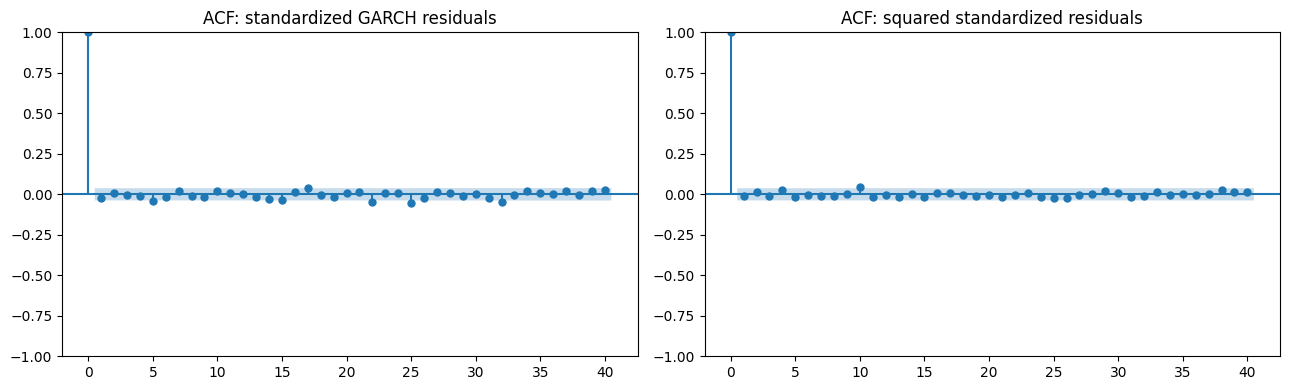

In [8]:
garch_diagnostic_fit = arch_model(
    fit_returns, mean="Constant", vol="GARCH", p=1, q=1, dist="normal"
).fit(disp="off")

print(garch_diagnostic_fit.summary())
print("Convergence flag (0 indicates successful convergence):", garch_diagnostic_fit.convergence_flag)

params = garch_diagnostic_fit.params
alpha = float(params.get("alpha[1]", np.nan))
beta = float(params.get("beta[1]", np.nan))
omega = float(params.get("omega", np.nan))
persistence = alpha + beta
print(f"omega={omega:.6g}, alpha={alpha:.4f}, beta={beta:.4f}, alpha+beta={persistence:.4f}")
if np.isfinite(persistence):
    if persistence < 1:
        print("alpha + beta < 1: consistent with the usual finite-unconditional-variance condition for GARCH(1,1).")
    else:
        print("alpha + beta >= 1: the usual finite-unconditional-variance condition is not satisfied.")

std_resid = pd.Series(garch_diagnostic_fit.std_resid, index=fit_returns.index).dropna()
resid_lb = acorr_ljungbox(std_resid, lags=[10, 20], return_df=True)
squared_resid_lb = acorr_ljungbox(std_resid**2, lags=[10, 20], return_df=True)
resid_arch_stat, resid_arch_pvalue, _, _ = het_arch(std_resid, nlags=10)
print("Ljung-Box on standardized residuals:")
display(resid_lb.round(4))
print("Ljung-Box on squared standardized residuals:")
display(squared_resid_lb.round(4))
print(f"ARCH-LM on standardized residuals: statistic={resid_arch_stat:.4f}, p-value={resid_arch_pvalue:.4g}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(std_resid, lags=40, ax=axes[0], title="ACF: standardized GARCH residuals")
plot_acf(std_resid**2, lags=40, ax=axes[1], title="ACF: squared standardized residuals")
plt.tight_layout()
plt.show()

The model converged successfully, and all estimated parameters are highly statistically significant. The high $\beta$ coefficient (0.78) indicates that past volatility strongly dictates current volatility, while the $\alpha$ coefficient (0.19) captures the impact of recent market shocks. Because their sum ($\alpha + \beta \approx 0.97$) is strictly less than 1, the model is mathematically stable and it confirms that while market volatility shocks are highly persistent, they will eventually mean-revert back to the historical average.

More importantly, the residual diagnostics do not detect significant remaining linear autocorrelation or ARCH effects at the tested lags. This supports the GARCH(1,1) specification, although it does not establish that the model captures every feature of the return distribution.

## Forecast Evaluation

Since true conditional variance is unobservable, we score our forecasts ($\hat{\sigma}_t^2$) against actual squared returns ($r_t^2$) acting as our proxy. We evaluate model accuracy using two loss functions, where lower scores indicate better performance:

* **Mean Squared Error (MSE):** A standard, symmetric metric that heavily penalizes large absolute forecasting errors.

$$MSE = \frac{1}{N}\sum_{t=1}^N (r_t^2 - \hat{\sigma}_t^2)^2$$


* **QLIKE (Quasi-Likelihood):** A specialized metric for volatility forecasting. It penalizes heavily under-predicting volatility, a critical feature for financial risk management. This will be the primary metric, used for making decisions.

$$QLIKE = \frac{1}{N}\sum_{t=1}^N \left( \log(\hat{\sigma}_t^2) + \frac{r_t^2}{\hat{\sigma}_t^2} \right)$$

In [9]:
def variance_forecast_mse(actual_returns, forecast_variance):
    """MSE between squared returns and forecast variance, aligned by date"""
    aligned = pd.concat(
        [
            (actual_returns**2).rename("squared_return"),
            forecast_variance.rename("forecast_variance"),
        ],
        axis=1,
        join="inner",
    ).dropna()

    if aligned.empty:
        raise ValueError("No overlapping observations to evaluate.")
    if (aligned["forecast_variance"] <= 0).any():
        raise ValueError("Forecast variances must be positive.")

    return ((aligned["squared_return"] - aligned["forecast_variance"]) ** 2).mean()


def qlike_daily_loss(actual_returns, forecast_variance):
    """QLIKE daily loss, omitting the constant term"""
    aligned = pd.concat(
        [
            (actual_returns**2).rename("squared_return"),
            forecast_variance.rename("forecast_variance"),
        ],
        axis=1,
        join="inner",
    ).dropna()

    if aligned.empty:
        raise ValueError("No overlapping observations to evaluate.")
    if (aligned["forecast_variance"] <= 0).any():
        raise ValueError("Forecast variances must be positive.")

    return (np.log(aligned["forecast_variance"]) + (
        aligned["squared_return"] / aligned["forecast_variance"]
    ))

def qlike_loss(actual_returns, forecast_variance):
    """QLIKE loss"""
    return qlike_daily_loss(actual_returns, forecast_variance).mean()

## Select rolling and EWMA settings on validation data

In [10]:
rolling_windows = [5, 10, 20, 40, 60]
rolling_validation_results = []

for window in rolling_windows:
    forecast = rolling_variance_forecast(train_returns, window).loc[validation_returns.index]
    rolling_validation_results.append({
        "Window": window,
        "Validation QLIKE": qlike_loss(validation_returns, forecast),
        "Validation MSE": variance_forecast_mse(validation_returns, forecast),
    })

rolling_validation = pd.DataFrame(rolling_validation_results).sort_values(
    "Validation QLIKE"
).reset_index(drop=True)

ewma_lambdas = [0.90, 0.94, 0.97, 0.99]
ewma_validation_results = []

for lam in ewma_lambdas:
    forecast = ewma_variance_forecast(train_returns, lam).loc[validation_returns.index]
    ewma_validation_results.append({
        "Lambda": lam,
        "Validation QLIKE": qlike_loss(validation_returns, forecast),
        "Validation MSE": variance_forecast_mse(validation_returns, forecast),
    })

ewma_validation = pd.DataFrame(ewma_validation_results).sort_values(
    "Validation QLIKE"
).reset_index(drop=True)

display(rolling_validation.round(4))
display(ewma_validation.round(4))

best_window = int(rolling_validation.iloc[0]["Window"])
best_lambda = float(ewma_validation.iloc[0]["Lambda"])
print(f"Selected rolling window by validation QLIKE: {best_window}")
print(f"Selected EWMA lambda by validation QLIKE: {best_lambda}")

,Window,Validation QLIKE,Validation MSE
0,60,1.1975,5.8888
1,40,1.2192,5.8430
2,20,1.2279,5.8725
3,10,1.3251,6.0288
4,5,1.6044,6.7261


,Lambda,Validation QLIKE,Validation MSE
0,0.94,1.1828,5.7683
1,0.97,1.1892,5.7875
2,0.90,1.2018,5.8417
3,0.99,1.3241,6.4989


Selected rolling window by validation QLIKE: 60
Selected EWMA lambda by validation QLIKE: 0.94


## Select the GARCH refit schedule on validation data

GARCH uses an expanding estimation window where each refit uses all returns available before the target date. We compare refitting every 20, 40 or 60 trading days. Between refits, parameters are fixed but the variance forecast continues to update.

The refit cadence is selected using validation QLIKE.

In [11]:
garch_refit_cadences = [20, 40, 60]
garch_validation_results = []

for cadence in garch_refit_cadences:
    forecast_frame = garch_periodic_forecast(
        return_series=returns,
        first_target=len(fit_returns),
        end_position=len(train_returns),
        refit_every=cadence,
    )
    forecast = forecast_frame["garch_variance"]
    garch_validation_results.append({
        "Refit every (days)": cadence,
        "Validation QLIKE": qlike_loss(validation_returns, forecast),
        "Validation MSE": variance_forecast_mse(validation_returns, forecast),
    })

garch_validation = pd.DataFrame(garch_validation_results).sort_values(
    "Validation QLIKE"
).reset_index(drop=True)
display(garch_validation.round(4))
best_refit_every = int(garch_validation.iloc[0]["Refit every (days)"])
print(f"Selected GARCH refit cadence by validation QLIKE: {best_refit_every} trading days")

,Refit every (days),Validation QLIKE,Validation MSE
0,20,1.1850,6.0188
1,40,1.1852,6.0159
2,60,1.1856,6.0211


Selected GARCH refit cadence by validation QLIKE: 20 trading days


## Generate final test forecasts

With the settings selected on validation data, we now generate one-step-ahead forecasts for the test period.

- The historical-variance baseline uses the variance of all pre-test returns.
- Rolling and EWMA forecasts can update using observed returns as the test period progresses.
- GARCH parameters are re-estimated at the selected cadence using only the returns available before each target date.

In [12]:
# Historical variance benchmark
baseline_test_forecast = pd.Series(
    train_returns.var(),
    index=test_returns.index,
    name="Historical variance",
)

# Forecasts
rolling_test_forecast = rolling_variance_forecast(
    returns, best_window
).loc[test_returns.index].rename("Rolling")

ewma_test_forecast = ewma_variance_forecast(
    returns, best_lambda
).loc[test_returns.index].rename("EWMA")

garch_test_frame = garch_periodic_forecast(
    return_series=returns,
    first_target=len(train_returns),
    end_position=len(returns),
    refit_every=best_refit_every,
)
garch_test_forecast = garch_test_frame["garch_variance"].rename("GARCH")

test_forecasts = {
    "Historical variance": baseline_test_forecast,
    f"Rolling ({best_window} days)": rolling_test_forecast,
    f"EWMA (lambda={best_lambda:.2f})": ewma_test_forecast,
    f"GARCH (refit every {best_refit_every} days)": garch_test_forecast,
}

# Check date misalignment, missing forecasts or invalid variances
for name, forecast in test_forecasts.items():
    assert forecast.index.equals(test_returns.index), f"Date mismatch: {name}"
    assert forecast.notna().all(), f"Missing forecast: {name}"
    assert (forecast > 0).all(), f"Non-positive variance: {name}"

print(f"Test observations: {len(test_returns)}")
print(f"Test period: {test_returns.index.min().date()} to {test_returns.index.max().date()}")

Test observations: 844
Test period: 2023-05-30 to 2026-10-08


We can check the convergence and estimated parameters of each GARCH refit during the test period to assess the numerical reliability and persistence of the fitted models.

Successful convergence (flag = 0) does not, by itself, guarantee that the model is correctly specified or produces accurate forecasts.

In [13]:
refit_diagnostics = garch_test_frame.drop_duplicates("last_parameter_refit").copy()
print("GARCH refits in test period:", len(refit_diagnostics))
print("Refits with nonzero convergence flag:", int((refit_diagnostics["convergence_flag"] != 0).sum()))
display(refit_diagnostics[[
    "last_parameter_refit", "convergence_flag", "mu", "omega", "alpha[1]", "beta[1]", "alpha_plus_beta"
]].round(4))

GARCH refits in test period: 43
Refits with nonzero convergence flag: 0


,last_parameter_refit,convergence_flag,mu,omega,alpha[1],beta[1],alpha_plus_beta
Date,,,,,,,
2023-05-30,2023-05-26,0,0.0775,0.0367,0.1762,0.7966,0.9728
2023-06-28,2023-06-27,0,0.0785,0.0366,0.1754,0.7970,0.9725
2023-07-27,2023-07-26,0,0.0797,0.0363,0.1749,0.7974,0.9724
2023-08-24,2023-08-23,0,0.0779,0.0363,0.1734,0.7986,0.9720
2023-09-22,2023-09-21,0,0.0769,0.0365,0.1735,0.7984,0.9719
2023-10-20,2023-10-19,0,0.0760,0.0363,0.1719,0.7998,0.9717
2023-11-17,2023-11-16,0,0.0766,0.0362,0.1712,0.8006,0.9718
2023-12-18,2023-12-15,0,0.0783,0.0364,0.1724,0.7988,0.9713
2024-01-18,2024-01-17,0,0.0775,0.0364,0.1712,0.7997,0.9709


The results say the following:

* **Convergence:** The model successfully converged during all refits. This means the optimization algorithm didn't break down as new market data was added to the expanding estimation window.

* **Parameter Stability:** The estimated parameters ($\alpha$ and $\beta$) remain steady across the entire test period.

* **Persistent Mean-Reversion:** $\alpha + \beta$ never crosses 1, so we can be confident that our dynamic GARCH model reliably enforces mean-reversion throughout the entire walk-forward forecast.

## Evaluate out-of-sample performance

We now calculate both MSE and QLIKE to test our forecasts. Lower values indicate better performance under each loss function.

In [14]:
performance_rows = []

for name, forecast in test_forecasts.items():
    performance_rows.append(
        {
            "Model": name,
            "Test MSE": variance_forecast_mse(test_returns, forecast),
            "Test QLIKE": qlike_loss(test_returns, forecast),
        }
    )

performance = pd.DataFrame(performance_rows)

baseline_mse = performance.loc[
    performance["Model"] == "Historical variance", "Test MSE"
].iloc[0]
performance["MSE improvement vs baseline (%)"] = (
    (baseline_mse - performance["Test MSE"]) / baseline_mse * 100
)

baseline_qlike = performance.loc[
    performance["Model"] == "Historical variance", "Test QLIKE"
].iloc[0]

performance["QLIKE difference vs baseline"] = (
    performance["Test QLIKE"] - baseline_qlike
)

display(performance.round(4))

,Model,Test MSE,Test QLIKE,MSE improvement vs baseline (%),QLIKE difference vs baseline
0,Historical variance,11.9478,0.9019,0.0000,0.0000
1,Rolling (60 days),11.9636,0.7607,-0.1322,-0.1412
2,EWMA (lambda=0.94),11.3517,0.6852,4.9895,-0.2167
3,GARCH (refit every 20 days),11.0121,0.6325,7.8319,-0.2694


GARCH obtains the lowest test MSE and QLIKE for this ticker in the period selected. This may vary in other settings. Its MSE is about 7.8% lower than the historical-variance benchmark, and its QLIKE is 0.2694 lower (0.6325 vs 0.9019). The rolling model has a lower QLIKE than the benchmark but a slightly higher MSE, so the ranking can depend on the loss function.

QLIKE changes are reported as absolute differences, not percentages. If returns are rescaled by a constant $c$ (for example decimals instead of percentage points), $\hat\sigma_t^2$ and $r_t^2$ both scale by $c^2$, so every QLIKE value shifts by $\log c^2$: differences between models are unchanged, but percentage changes are not. MSE scales by $c^4$, so its percentage changes do not depend on units.

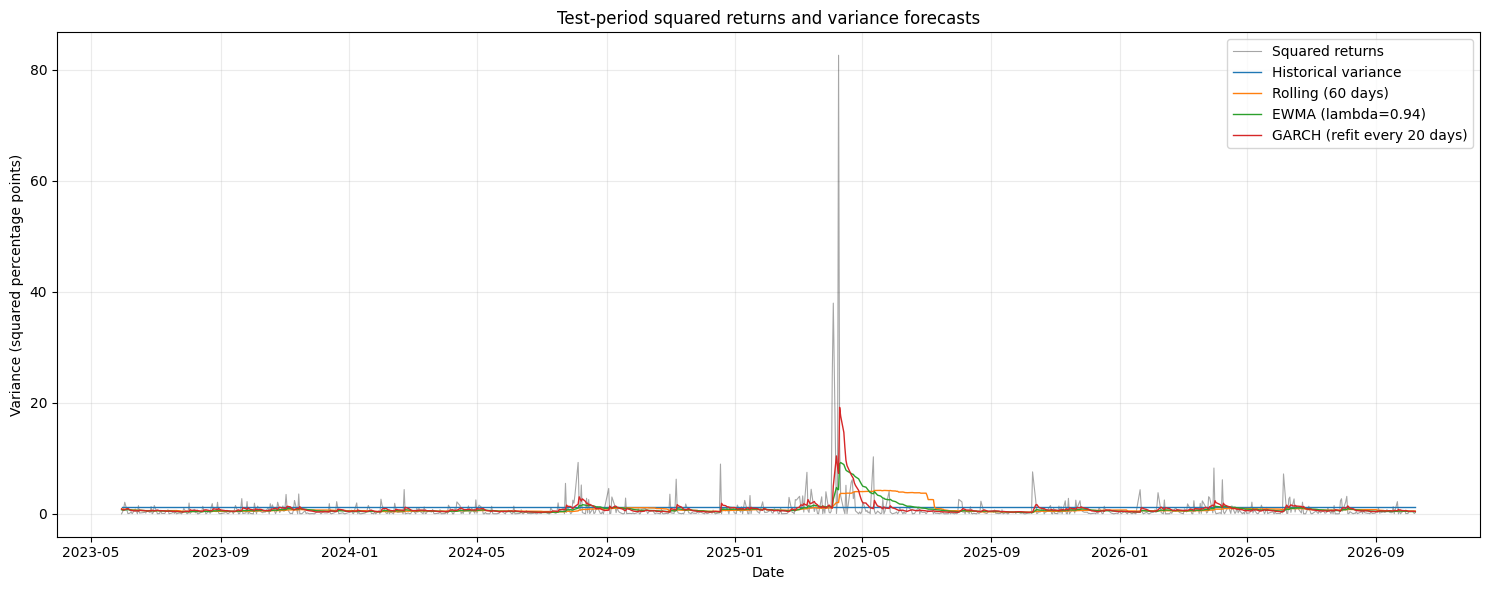

In [15]:
# Plot squared returns and forecast variances
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(
    test_returns.index,
    test_returns**2,
    label="Squared returns",
    color="black",
    alpha=0.35,
    linewidth=0.8,
)

for name, forecast in test_forecasts.items():
    ax.plot(forecast.index, forecast, label=name, linewidth=1)

ax.set_title("Test-period squared returns and variance forecasts")
ax.set_xlabel("Date")
ax.set_ylabel("Variance (squared percentage points)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

A one-step-ahead variance forecast is an expectation, not a prediction of the exact next squared return. Large squared-return spikes can therefore exceed the forecast by a wide margin.

## Diebold–Mariano-style comparison: GARCH vs EWMA

We compare daily QLIKE losses using the differential

$$
d_t = L_{GARCH,t} - L_{EWMA,t}
$$

The null hypothesis is $H_0: E[d_t]=0$, against the two-sided alternative $H_1: E[d_t]\ne0$. A negative mean difference favors GARCH.

The calculation below uses a HAC (Heteroskedasticity and Autocorrelation Consistent) estimate of the long-run variance of the loss differential and a normal reference distribution.

In [16]:
garch_name = f"GARCH (refit every {best_refit_every} days)"
ewma_name = f"EWMA (lambda={best_lambda:.2f})"

daily_losses = pd.DataFrame(
    {
        "GARCH QLIKE": qlike_daily_loss(
            test_returns, test_forecasts[garch_name]
        ),
        "EWMA QLIKE": qlike_daily_loss(
            test_returns, test_forecasts[ewma_name]
        ),
    }
).dropna()

assert daily_losses.index.equals(test_returns.index)

daily_losses["loss_difference"] = (
    daily_losses["GARCH QLIKE"] - daily_losses["EWMA QLIKE"]
)

print("Matched observations:", len(daily_losses))
print("Mean GARCH QLIKE:", daily_losses["GARCH QLIKE"].mean())
print("Mean EWMA QLIKE:", daily_losses["EWMA QLIKE"].mean())
print("Mean loss difference:", daily_losses["loss_difference"].mean())

Matched observations: 844
Mean GARCH QLIKE: 0.632458680206351
Mean EWMA QLIKE: 0.6852404232181128
Mean loss difference: -0.052781743011761875


In [17]:
d = daily_losses["loss_difference"].to_numpy()
X = np.ones((len(d), 1))
hac_rows = []

for lag in [5, 10, 20]:
    fitted = sm.OLS(d, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": lag},
    )
    statistic = float(fitted.params[0] / fitted.bse[0])
    p_value = float(2 * norm.sf(abs(statistic)))

    hac_rows.append(
        {
            "HAC max lags": lag,
            "Mean loss difference": float(fitted.params[0]),
            "Test statistic": statistic,
            "Two-sided p-value": p_value,
            "Significant at 5%": p_value < 0.05,
        }
    )

hac_sensitivity = pd.DataFrame(hac_rows)
display(hac_sensitivity.round(4))

,HAC max lags,Mean loss difference,Test statistic,Two-sided p-value,Significant at 5%
0,5,-0.0528,-2.4263,0.0153,True
1,10,-0.0528,-2.5186,0.0118,True
2,20,-0.0528,-2.4357,0.0149,True


As the p-value is below 0.05, we reject equal expected QLIKE loss under that test specification. Similar conclusions across the selected HAC lags are reassuring, but do not prove that all assumptions hold. In particular, the GARCH parameters are periodically re-estimated, and daily loss differences may remain dependent over time.

## Calm vs turbulent periods

We can classify each test day using the standard deviation of the previous 20 returns. The threshold is the 75th percentile of this measure during the pre-test training period and is held fixed throughout the test period.
This avoids using the target day's return to classify its own regime.

In [18]:
REGIME_WINDOW = 20

trailing_volatility = returns.rolling(REGIME_WINDOW).std().shift(1)

regime_threshold = trailing_volatility.loc[train_returns.index].quantile(0.75)

test_regimes = pd.DataFrame(
    {
        "trailing_volatility": trailing_volatility.loc[test_returns.index],
    },
    index=test_returns.index,
).dropna()

test_regimes["regime"] = np.where(
    test_regimes["trailing_volatility"] > regime_threshold,
    "Turbulent",
    "Calm",
)

print(f"Training-period 75th percentile threshold: {regime_threshold:.4f}")
display(
    test_regimes.groupby("regime").agg(
        observations=("trailing_volatility", "size"),
        average_trailing_volatility=("trailing_volatility", "mean"),
    ).round(4)
)

Training-period 75th percentile threshold: 1.1579


,observations,average_trailing_volatility
regime,,
Calm,769,0.7389
Turbulent,75,1.7865


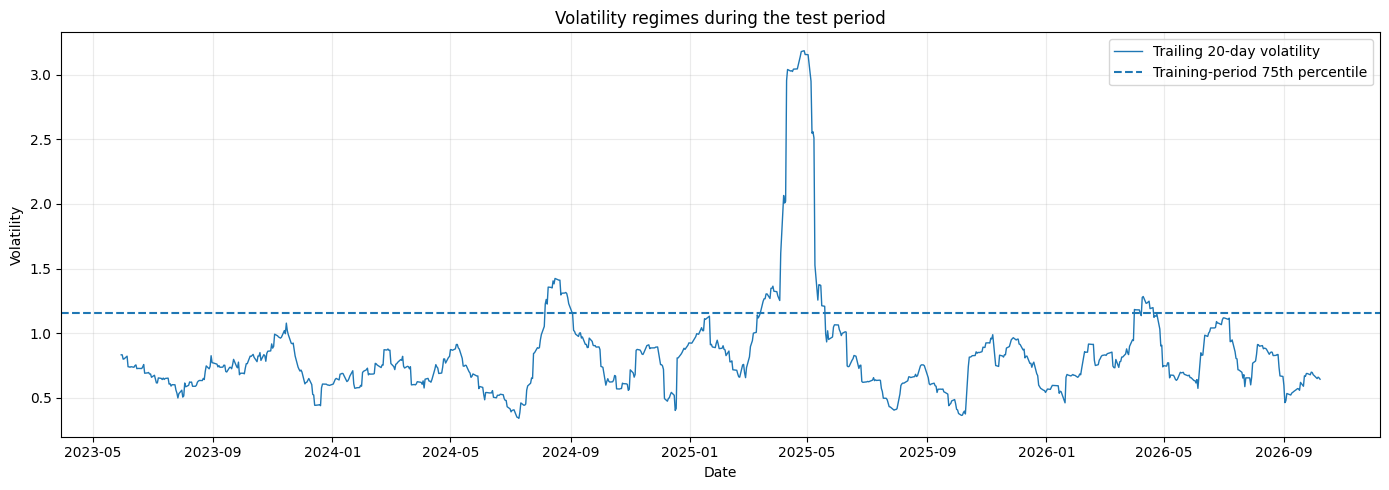

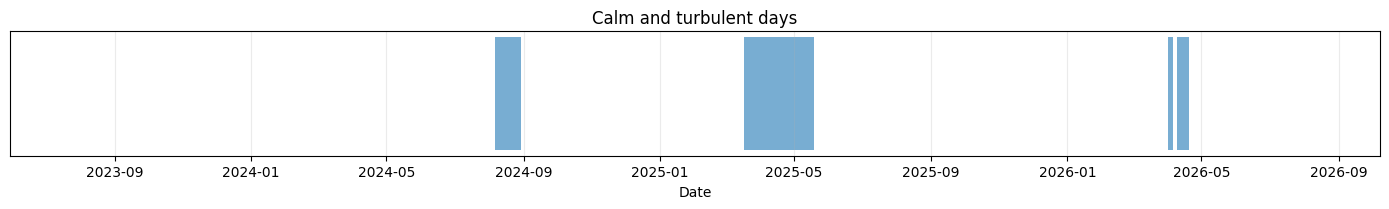

In [19]:
# Volatility level and threshold over the test timeline
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(
    test_regimes.index,
    test_regimes["trailing_volatility"],
    label=f"Trailing {REGIME_WINDOW}-day volatility",
    linewidth=1,
)
ax.axhline(
    regime_threshold,
    linestyle="--",
    label="Training-period 75th percentile",
)
ax.set_title("Volatility regimes during the test period")
ax.set_xlabel("Date")
ax.set_ylabel("Volatility")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

is_turbulent = test_regimes["regime"].eq("Turbulent")
fig, ax = plt.subplots(figsize=(14, 2.2))
ax.fill_between(
    test_regimes.index,
    0,
    1,
    where=is_turbulent.to_numpy(),
    step="mid",
    alpha=0.6,
)
ax.set_xlim(test_regimes.index.min(), test_regimes.index.max())
ax.set_yticks([])
ax.set_title("Calm and turbulent days")
ax.set_xlabel("Date")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

In [20]:
# Compare daily QLIKE losses within each regime
regime_comparison = daily_losses.join(
    test_regimes["regime"],
    how="inner",
)

regime_results = (
    regime_comparison
    .groupby("regime")
    .agg(
        observations=("loss_difference", "size"),
        GARCH_QLIKE=("GARCH QLIKE", "mean"),
        EWMA_QLIKE=("EWMA QLIKE", "mean"),
        mean_loss_difference=("loss_difference", "mean"),
    )
)

display(regime_results.round(4))

,observations,GARCH_QLIKE,EWMA_QLIKE,mean_loss_difference
regime,,,,
Calm,769,0.5053,0.5515,-0.0462
Turbulent,75,1.9362,2.0569,-0.1208


In both the calm and turbulent subsets, GARCH has a lower mean QLIKE loss than EWMA. The mean loss difference is larger in the turbulent subset (-0.1208 vs -0.0462 in the calm one). Percentage reductions are not reported, because QLIKE percentages depend on the units of returns (see the test evaluation above). The turbulent subset contains only 75 observations, so this is descriptive evidence, not proof that GARCH's advantage is larger in turbulent markets.

## Summary and limitations

**Interpretation:**
- Evidence of autocorrelation in squared returns supports volatility clustering.
- Ljung-Box also rejects no autocorrelation in raw returns. This dependence is small, and the notebook does not test whether it could be exploited, so it is not evidence against the weak-form EMH.
- Among the tested models, GARCH has the lowest test MSE and QLIKE for the data used. Its mean daily QLIKE advantage over EWMA (-0.0528) is significant at 5% in a Diebold–Mariano-style test with HAC errors (p between 0.012 and 0.015 for 5, 10 and 20 lags).
- These results don't mean that return direction is fully unpredictable or that a model will always win.

**Limitations:**
- Squared returns are noisy proxies for latent variance.
- EWMA assumes a zero mean, rolling variance subtracts its window mean and GARCH estimates a constant mean with normal innovations, but all forecasts are scored against $r_t^2$. The effect is small ($\hat\mu^2 \approx 0.006$).
- The regime analysis is exploratory and its turbulent subset is small.
- Results are specific to the S&P 500 sample and the selected design.
- GJR-GARCH/EGARCH could model asymmetric responses to negative shocks, but are left out to keep this first comparison focused on three transparent, symmetric variance forecasts. They are a natural extension rather than necessary for answering the current research question.
- The HAC comparison provides asymptotic evidence about mean loss differences under its assumptions, not a guarantee of universal model superiority.